<a href="https://colab.research.google.com/github/suriarasai/BEAD2026/blob/main/colab/rebu/01IngestionCleansingDataQuality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Ingestion, Cleansing & Data Quality  (Bronze ➜ Silver)
**Business outcome:** a trusted, PDPA-safe *silver* layer plus a **data-quality scorecard**, so every dashboard built later states how far its numbers can be trusted.

| # | UDF | Kind | What it solves |
|---|-----|------|----------------|
| 1 | `parse_flexible_ts` | Python UDF → `timestamp` | Mixed date formats across source systems (day-first vs ISO) |
| 2 | `normalize_sg_phone` | Python UDF → `struct` | Canonical E.164 numbers + line-type validation for CRM matching |
| 3 | `parse_sg_address` | Python UDF → `struct` | Splits HDB-style addresses; derives district/region; flags inconsistent postcodes |
| 4 | `mask_email` / `mask_phone` | pandas UDF / Python UDF | PDPA-compliant masking for analyst-facing tables |
| 5 | `make_dq_udf(rules)` | UDF **factory** → `array<string>` | Configurable, row-level data-quality rule engine |

Note: **When *not* to write a UDF:** Spark built-ins run inside the JVM; Python UDFs ship every row to a Python worker. Section 2 measures the gap, so you can see why the rest of the series uses UDFs only where built-ins can't express the logic.

## Setup
Run these four cells first. In Colab, you'll be asked to authorise Google Drive.

In [9]:
#@title 1 · Environment (PySpark + Java) — run once { display-mode: "form" }
import os, sys, re, glob, time, subprocess, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

def _java_major():
    try:
        out = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
        m = re.search(r'version "(\d+)(?:\.(\d+))?', out)
        major = int(m.group(1))
        return int(m.group(2)) if major == 1 else major
    except Exception:
        return None

try:
    import pyspark
except ImportError:                      # recent Colab images ship PySpark; install only if missing
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.5"], check=True)
    import pyspark

_spark_major, _jv = int(pyspark.__version__.split(".")[0]), _java_major()
# Spark 3.5 runs on Java 8/11/17, Spark 4.x on Java 17/21 → fix the JDK on Colab if they don't match
if IN_COLAB and (_jv is None or (_spark_major < 4 and _jv > 17) or (_spark_major >= 4 and _jv < 17)):
    subprocess.run("apt-get -qq update && apt-get -qq install -y openjdk-17-jdk-headless > /dev/null",
                   shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

print(f"PySpark {pyspark.__version__} · Java {_java_major()} · Colab={IN_COLAB}")

PySpark 4.0.4 · Java 21 · Colab=True


In [10]:
#@title 2 · Point to the data { display-mode: "form" }
#@markdown Put the 9 CSV files (Booking, Payment, Rewards, Passengers, Drivers, Taxi, TaxiType, Place, PaymentType)
#@markdown in one Google Drive folder and set its path here. File names may carry a prefix (e.g. `2eaaf3ac-Passengers.csv`).
DATA_DIR = "/content/drive/MyDrive/rebu"  #@param {type:"string"}
TABLES = ["Booking", "Payment", "Rewards", "Passengers", "Drivers", "Taxi", "TaxiType", "Place", "PaymentType"]

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not glob.glob(os.path.join(DATA_DIR, "*.csv")):
        print(f"No CSVs in {DATA_DIR} – falling back to direct upload (Drive is faster for the ~50 MB files).")
        from google.colab import files
        DATA_DIR = "/content/data"; os.makedirs(DATA_DIR, exist_ok=True)
        for fname, blob in files.upload().items():
            with open(os.path.join(DATA_DIR, fname), "wb") as fh:
                fh.write(blob)
else:
    DATA_DIR = os.environ.get("SG_TAXI_DATA", "./data")

LAKE_DIR = os.path.join(DATA_DIR, "lakehouse")      # bronze / silver / gold outputs land here

def find_csv(name):
    """Match 'Taxi.csv' or '<prefix>-Taxi.csv' but never 'TaxiType.csv'."""
    hits = [p for p in glob.glob(os.path.join(DATA_DIR, "*.csv"))
            if re.fullmatch(rf"(?:.*[-_ ])?{name}\.csv", os.path.basename(p), flags=re.I)]
    if not hits:
        raise FileNotFoundError(f"{name}.csv not found in {DATA_DIR}")
    return hits[0]

for t in TABLES:
    print(f"{t:<12} → {os.path.basename(find_csv(t))}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Booking      → Booking.csv
Payment      → Payment.csv
Rewards      → Rewards.csv
Passengers   → Passengers.csv
Drivers      → Drivers.csv
Taxi         → Taxi.csv
TaxiType     → TaxiType.csv
Place        → Place.csv
PaymentType  → PaymentType.csv


In [11]:
#@title 3 · Spark session, readers & chart style { display-mode: "form" }
from pyspark.sql import SparkSession, Window, functions as F, types as T
import pandas as pd, numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
from IPython.display import display, Markdown

# --add-opens lets Arrow (used by pandas UDFs) work on newer JDKs; harmless on Java 11
_JOPTS = " ".join(f"--add-opens=java.base/{p}=ALL-UNNAMED"
                  for p in ["java.nio", "sun.nio.ch", "java.lang", "java.util"]) + " -Dio.netty.tryReflectionSetAccessible=true"
spark = (SparkSession.builder.appName("SG-Taxi-BI-UDFs").master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "Asia/Singapore")
         .config("spark.sql.execution.arrow.pyspark.enabled", "true")
         .config("spark.driver.extraJavaOptions", _JOPTS)
         .config("spark.executor.extraJavaOptions", _JOPTS)
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

def read_csv(name):
    """Bronze read: every column as a raw string, delimiter sniffed (Booking.csv is tab-separated)."""
    path = find_csv(name)
    with open(path, encoding="utf-8-sig") as fh:
        header = fh.readline()
    sep = "\t" if header.count("\t") > header.count(",") else ","
    return spark.read.csv(path, header=True, sep=sep, inferSchema=False, quote='"', escape='"')

def show(df, n=10):
    """Pretty table in Colab (Spark → pandas for display only)."""
    display(df.limit(n).toPandas())

def timed(label, df):
    """Force full evaluation without collecting (noop sink) and time it."""
    t0 = time.perf_counter()
    df.write.format("noop").mode("overwrite").save()
    secs = time.perf_counter() - t0
    print(f"{label:<48}{secs:7.2f} s")
    return secs

# Chart style: thin marks, recessive grid, fixed categorical order, single-hue sequential ramp
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = mpl.colors.LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
mpl.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE), "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 10, "axes.axisbelow": True,
})
print("Spark", spark.version, "ready")

Spark 4.0.4 ready


## 1 · Bronze — land the raw files as strings
Bronze keeps the source **exactly** as delivered (all strings), so nothing is lost before we decide how to parse it.

In [12]:
raw = {t: read_csv(t) for t in TABLES}
for t, df in raw.items():
    print(f"{t:<12}{df.count():>10,} rows   cols: {', '.join(df.columns)}")

Booking        505,630 rows   cols: BookingID, PassengerID, DriverID, TaxiID, PickupPlaceID, DropoffPlaceID, BookingDateTime, PickupTime, DropoffTime, Distance, Fare, Status
Payment        962,068 rows   cols: PaymentID, BookingID, PaymentTypeID, Amount, PaymentDateTime, Status
Rewards        931,164 rows   cols: RewardID, PassengerID, Points, EarnedDate, Description
Passengers       1,000 rows   cols: PassengerID, FirstName, LastName, Phone, Email, MemberCategory, Age, Gender, Address, RegistrationDate
Drivers            400 rows   cols: DriverID, FirstName, LastName, Phone, Email, LicenseNumber, Age, Gender, YearsExperience, Rating, JoinDate
Taxi               400 rows   cols: TaxiID, LicensePlate, TaxiTypeID, Model, YearManufactured, Status
TaxiType             5 rows   cols: TaxiTypeID, TypeName, BaseFare, PerKmRate, Capacity
Place               87 rows   cols: PlaceID, PlaceName, Latitude, Longitude, PostalCode
PaymentType          6 rows   cols: PaymentTypeID, TypeName


In [13]:
show(raw["Booking"], 5)
show(raw["Payment"], 5)

,BookingID,PassengerID,DriverID,TaxiID,PickupPlaceID,DropoffPlaceID,BookingDateTime,PickupTime,DropoffTime,Distance,Fare,Status
0,1,317,79,79,80,58,1/8/2023 15:55,1/8/2023 16:00,1/8/2023 16:26,14.29,13.08,Completed
1,2,194,359,359,54,19,1/7/2023 2:35,1/7/2023 2:39,1/7/2023 3:18,16.68,21.76,Completed
2,3,209,213,213,56,60,17/4/2024 3:39,17/4/2024 3:48,17/4/2024 4:27,18.34,27.51,Completed
3,4,737,65,65,65,74,2/6/2024 6:25,2/6/2024 6:29,2/6/2024 6:51,11.55,15.38,Completed
4,5,703,300,300,15,7,25/9/2023 4:23,25/9/2023 4:29,25/9/2023 4:59,13.87,17.29,Completed


,PaymentID,BookingID,PaymentTypeID,Amount,PaymentDateTime,Status
0,1,1,2,13.08,2023-08-01 16:26:00,Completed
1,2,2,5,21.76,2023-07-01 03:19:00,Completed
2,3,3,5,27.51,2024-04-17 04:28:00,Completed
3,4,4,4,15.38,2024-06-02 06:53:00,Completed
4,5,5,1,17.29,2023-09-25 05:00:00,Completed


**What the bronze layer tells us**
* `Booking.csv` is **tab-delimited** and uses **day-first** dates (`17/4/2024 3:39`); `Payment.csv` uses ISO timestamps. A naive parser either fails or silently swaps day and month.
* `Rewards.Description` hides a foreign key inside free text (`Earned from booking #123`).
* Passenger addresses pack block, street, unit and postcode into one string.

## 2 · UDF #1 `parse_flexible_ts`: one parser for every source format

In [14]:
from datetime import datetime

TS_FORMATS = ("%d/%m/%Y %H:%M", "%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M", "%Y-%m-%d", "%d/%m/%Y")

@F.udf(T.TimestampType())
def parse_flexible_ts(s):
    """Try each known source format in order; return None (not an exception) when nothing fits."""
    if s is None:
        return None
    s = s.strip()
    for fmt in TS_FORMATS:
        try:
            return datetime.strptime(s, fmt)
        except ValueError:
            continue
    return None

demo = spark.createDataFrame([("17/4/2024 3:39",), ("2023-08-01 16:26:00",), ("2024-04-17",), ("31/02/2024 10:00",), ("garbage",)], ["raw"])
show(demo.withColumn("parsed", parse_flexible_ts("raw")))

,raw,parsed
0,17/4/2024 3:39,2024-04-17 11:39:00
1,2023-08-01 16:26:00,2023-08-02 00:26:00
2,2024-04-17,2024-04-17 08:00:00
3,31/02/2024 10:00,NaT
4,garbage,NaT


In [15]:
bk = raw["Booking"].select("BookingID", *[parse_flexible_ts(c).alias(c) for c in ["BookingDateTime", "PickupTime", "DropoffTime"]])
pay = raw["Payment"].select("PaymentID", parse_flexible_ts("PaymentDateTime").alias("PaymentTS"))
print("Unparseable booking timestamps:", bk.filter(F.col("BookingDateTime").isNull() | F.col("PickupTime").isNull() | F.col("DropoffTime").isNull()).count())
print("Unparseable payment timestamps:", pay.filter(F.col("PaymentTS").isNull()).count())
bk.agg(F.min("BookingDateTime").alias("first_booking"), F.max("BookingDateTime").alias("last_booking")).show(truncate=False)

Unparseable booking timestamps: 0
Unparseable payment timestamps: 0
+-------------------+-------------------+
|first_booking      |last_booking       |
+-------------------+-------------------+
|2023-01-01 08:01:00|2025-01-08 07:59:00|
+-------------------+-------------------+



### Performance check: Python UDF vs Spark built-in
The same logic written with `try_to_timestamp` + `coalesce` never leaves the JVM.

In [16]:
FMTS_SPARK = ["d/M/yyyy H:mm", "yyyy-MM-dd HH:mm:ss", "yyyy-MM-dd HH:mm", "yyyy-MM-dd"]
def builtin_ts(c):
    return F.coalesce(*[F.try_to_timestamp(F.col(c), F.lit(f)) for f in FMTS_SPARK])

src = raw["Booking"].select("BookingDateTime", "PickupTime", "DropoffTime").cache(); src.count()
t_udf = timed("Python UDF  (3 cols × 505k rows)", src.select(*[parse_flexible_ts(c) for c in src.columns]))
t_bi  = timed("Built-in    (3 cols × 505k rows)", src.select(*[builtin_ts(c) for c in src.columns]))
print(f"→ built-in is ~{t_udf / max(t_bi, 1e-6):.1f}× faster here")

same = src.select((parse_flexible_ts("PickupTime") == builtin_ts("PickupTime")).alias("eq")).agg(F.avg(F.col("eq").cast("int"))).first()[0]
print(f"Results identical on {same:.2%} of rows")

Python UDF  (3 cols × 505k rows)                  17.32 s
Built-in    (3 cols × 505k rows)                   0.88 s
→ built-in is ~19.6× faster here
Results identical on 0.00% of rows


**Takeaway:** keep the UDF for *messy, rule-heavy* parsing you can't express in SQL, and use built-ins when they exist. The rest of this series follows that rule: UDFs carry domain logic (tariffs, segmentation, geo rules), built-ins do plumbing.

## 3 · UDF #2 `normalize_sg_phone`: canonical numbers for CRM matching
Returns a **struct**, so one call yields three columns (E.164 number, line type, validity).

In [17]:
phone_schema = T.StructType([
    T.StructField("e164", T.StringType()),
    T.StructField("line_type", T.StringType()),
    T.StructField("is_valid", T.BooleanType()),
])
SG_PREFIX = {"8": "mobile", "9": "mobile", "6": "landline", "3": "VoIP"}

@F.udf(phone_schema)
def normalize_sg_phone(raw_phone):
    if raw_phone is None:
        return (None, "missing", False)
    digits = re.sub(r"\D", "", raw_phone)
    if len(digits) == 10 and digits.startswith("65"):
        digits = digits[2:]                       # strip country code
    if len(digits) != 8 or digits[0] not in SG_PREFIX:
        return (None, "invalid", False)
    return ("+65" + digits, SG_PREFIX[digits[0]], True)

messy = spark.createDataFrame([("+65 9205 6777",), ("6592056777",), ("92056777",), ("(65) 6123-4567",),
                               ("+6531234567",), ("12345",), ("+6551234567",), (None,)], "raw string")
show(messy.withColumn("p", normalize_sg_phone("raw")).select("raw", "p.*"))

,raw,e164,line_type,is_valid
0,+65 9205 6777,+6592056777,mobile,True
1,6592056777,+6592056777,mobile,True
2,92056777,+6592056777,mobile,True
3,(65) 6123-4567,+6561234567,landline,True
4,+6531234567,+6531234567,VoIP,True
5,12345,None,invalid,False
6,+6551234567,None,invalid,False
7,None,None,missing,False


In [18]:
contacts = (raw["Drivers"].select(F.lit("driver").alias("who"), "Phone")
            .unionByName(raw["Passengers"].select(F.lit("passenger").alias("who"), "Phone"))
            .withColumn("p", normalize_sg_phone("Phone")))
show(contacts.groupBy("who", "p.line_type", "p.is_valid").count().orderBy("who"))
dupes = contacts.filter("p.is_valid").groupBy("p.e164").count().filter("count > 1").count()
print("Phone numbers shared by >1 person:", dupes)

,who,line_type,is_valid,count
0,driver,mobile,True,400
1,passenger,mobile,True,1000


Phone numbers shared by >1 person: 0


## 4 · UDF #3  `parse_sg_address`: structure + geography + consistency check

In [19]:
#@title Singapore reference: postal sectors → districts → regions, place categories { display-mode: "form" }
# URA postal districts: first two digits of a 6-digit postcode ("sector") identify the district (1–28).
_DISTRICT_SECTORS = {1: "01 02 03 04 05 06", 2: "07 08", 3: "14 15 16", 4: "09 10", 5: "11 12 13", 6: "17",
                     7: "18 19", 8: "20 21", 9: "22 23", 10: "24 25 26 27", 11: "28 29 30", 12: "31 32 33",
                     13: "34 35 36 37", 14: "38 39 40 41", 15: "42 43 44 45", 16: "46 47 48", 17: "49 50 81",
                     18: "51 52", 19: "53 54 55 82", 20: "56 57", 21: "58 59", 22: "60 61 62 63 64",
                     23: "65 66 67 68", 24: "69 70 71", 25: "72 73", 26: "77 78", 27: "75 76", 28: "79 80"}
SECTOR_TO_DISTRICT = {s: d for d, secs in _DISTRICT_SECTORS.items() for s in secs.split()}
# Approximate grouping of districts into the five planning regions (good enough for BI roll-ups)
DISTRICT_TO_REGION = {**{d: "Central" for d in (1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 12, 13)},
                      **{d: "East" for d in (14, 15, 16, 17, 18)},
                      **{d: "West" for d in (5, 21, 22, 23, 24)},
                      **{d: "North" for d in (25, 26, 27)},
                      **{d: "North-East" for d in (19, 20, 28)}}
REGIONS = ["Central", "East", "North-East", "North", "West"]

# Ordered keyword rules → first match wins
PLACE_CATEGORY_RULES = [
    ("Airport",               r"airport"),
    ("Hospital",              r"hospital"),
    ("University",            r"^(nus|ntu|smu|sutd)$"),
    ("Business / Industrial", r"business park|industrial|science park|one-north|jurong island"),
    ("Attraction",            r"sentosa|gardens|zoo|universal|safari|bird park|esplanade|merlion|fort canning|marina bay sands|clarke quay"),
    ("Mall",                  r"vivocity|ion orchard|ngee ann|suntec|junction|plaza singapura|funan|^imm$|^jem$|westgate|orchard road"),
    ("CBD",                   r"raffles place|city hall|chinatown|tanjong pagar"),
]

geo_schema = T.StructType([T.StructField("postal_district", T.IntegerType()),
                           T.StructField("region", T.StringType()),
                           T.StructField("postal_valid", T.BooleanType())])

@F.udf(geo_schema)
def postal_geo(postal):
    """6-digit SG postcode → (district, region, valid?)."""
    if not postal or not re.fullmatch(r"\d{6}", postal.strip()):
        return (None, None, False)
    d = SECTOR_TO_DISTRICT.get(postal.strip()[:2])
    return (d, DISTRICT_TO_REGION.get(d), d is not None)

@F.udf("string")
def place_category(name):
    """Keyword classifier for points of interest."""
    n = (name or "").strip().lower()
    for label, pattern in PLACE_CATEGORY_RULES:
        if re.search(pattern, n):
            return label
    return "Town / MRT hub"

In [20]:
# Street-name stems → (planning area, region). Longest match wins, so "Jurong East" beats "Jurong".
STREET_TOWN = {
    "Ang Mo Kio": ("Ang Mo Kio", "North-East"), "Balestier": ("Novena", "Central"), "Bayshore": ("Bedok", "East"),
    "Bedok": ("Bedok", "East"), "Bishan": ("Bishan", "Central"), "Broadrick": ("Geylang", "Central"),
    "Bukit Batok": ("Bukit Batok", "West"), "Bukit Panjang": ("Bukit Panjang", "West"), "Clementi": ("Clementi", "West"),
    "Dedap": ("Serangoon", "North-East"), "Dorset": ("Kallang", "Central"), "Dover": ("Queenstown", "Central"),
    "Elias": ("Pasir Ris", "East"), "Eunos": ("Geylang", "Central"), "Gangsa": ("Bukit Panjang", "West"),
    "Hindhede": ("Bukit Timah", "Central"), "Hougang": ("Hougang", "North-East"), "Jurong East": ("Jurong East", "West"),
    "Jurong": ("Jurong West", "West"), "Kim Keat": ("Toa Payoh", "Central"), "Kismis": ("Bukit Timah", "Central"),
    "Lengkong": ("Bedok", "East"), "Lower Delta": ("Bukit Merah", "Central"), "Marine": ("Marine Parade", "Central"),
    "Pasir Ris": ("Pasir Ris", "East"), "Petir": ("Bukit Panjang", "West"), "Sembawang": ("Sembawang", "North"),
    "Shunfu": ("Bishan", "Central"), "Tampines": ("Tampines", "East"), "Telok Blangah": ("Bukit Merah", "Central"),
    "Toa Payoh": ("Toa Payoh", "Central"), "Towner": ("Kallang", "Central"), "Ubi": ("Geylang", "Central"),
    "Upper Paya Lebar": ("Serangoon", "North-East"), "Westwood": ("Jurong West", "West"), "Woodlands": ("Woodlands", "North"),
    "Yishun": ("Yishun", "North"), "Zion": ("River Valley", "Central"),
}
_STREET_KEYS = sorted(STREET_TOWN, key=len, reverse=True)
ADDR_RE = re.compile(r"^(?:Blk|Block)\s*(?P<blk>\w+),\s*(?P<street>[^,#]+?),\s*#(?P<floor>\d+)-(?P<unit>\d+),\s*Singapore\s*(?P<postal>\d{6})$", re.I)

addr_schema = T.StructType([T.StructField(n, t) for n, t in [
    ("block", T.StringType()), ("street", T.StringType()), ("floor", T.IntegerType()), ("unit", T.StringType()),
    ("postal_code", T.StringType()), ("postal_district", T.IntegerType()), ("postal_region", T.StringType()),
    ("street_town", T.StringType()), ("street_region", T.StringType()),
    ("postal_valid", T.BooleanType()), ("region_consistent", T.BooleanType()), ("parsed", T.BooleanType())]])

@F.udf(addr_schema)
def parse_sg_address(addr):
    m = ADDR_RE.match((addr or "").strip())
    if not m:
        return (None,) * 11 + (False,)
    street, postal = m["street"].strip(), m["postal"]
    district = SECTOR_TO_DISTRICT.get(postal[:2])
    p_region = DISTRICT_TO_REGION.get(district)
    key = next((k for k in _STREET_KEYS if street.lower().startswith(k.lower())), None)
    town, s_region = STREET_TOWN.get(key, (None, None))
    consistent = None if (p_region is None or s_region is None) else (p_region == s_region)
    return (m["blk"], street, int(m["floor"]), m["unit"], postal, district, p_region, town, s_region,
            district is not None, consistent, True)

addr = raw["Passengers"].select("PassengerID", "Address", parse_sg_address("Address").alias("a")).select("PassengerID", "Address", "a.*").cache()
show(addr, 6)

,PassengerID,Address,block,street,floor,unit,postal_code,postal_district,postal_region,street_town,street_region,postal_valid,region_consistent,parsed
0,1,"Blk 812, Sembawang Drive, #12-33, Singapore 88...",812,Sembawang Drive,12,33,882802,NaN,None,Sembawang,North,False,None,True
1,2,"Blk 667, Jurong East Street, #15-719, Singapor...",667,Jurong East Street,15,719,119775,5.0,West,Jurong East,West,True,True,True
2,3,"Blk 564, Telok Blangah Crescent, #09-64, Singa...",564,Telok Blangah Crescent,9,64,641580,22.0,West,Bukit Merah,Central,True,False,True
3,4,"Blk 628, Toa Payoh North, #03-510, Singapore 3...",628,Toa Payoh North,3,510,327179,12.0,Central,Toa Payoh,Central,True,True,True
4,5,"Blk 607, Bedok North Rd, #21-284, Singapore 21...",607,Bedok North Rd,21,284,211844,8.0,Central,Bedok,East,True,False,True
5,6,"Blk 84, Bedok North Rd, #06-539, Singapore 755820",84,Bedok North Rd,6,539,755820,27.0,North,Bedok,East,True,False,True


In [21]:
s = addr.agg(F.avg(F.col("parsed").cast("int")).alias("parsed"),
             F.avg(F.col("postal_valid").cast("int")).alias("postal_valid"),
             F.avg(F.col("region_consistent").cast("int")).alias("region_consistent_when_valid"),
             F.avg(F.col("street_region").isNotNull().cast("int")).alias("street_town_resolved")).first()
for k, v in s.asDict().items():
    print(f"{k:<30}{v:8.1%}")
print("\nStreet-derived region × postcode-derived region:")
show(addr.withColumn("postal_region", F.coalesce("postal_region", F.lit("Invalid postcode")))
         .groupBy("street_region").pivot("postal_region", REGIONS + ["Invalid postcode"]).count()
         .orderBy("street_region").fillna(0), 10)

parsed                          100.0%
postal_valid                     80.1%
region_consistent_when_valid     26.0%
street_town_resolved            100.0%

Street-derived region × postcode-derived region:


,street_region,Central,East,North-East,North,West,Invalid postcode
0,Central,127,81,31,25,84,93
1,East,49,31,35,6,39,42
2,North,13,10,8,4,17,8
3,North-East,28,18,5,7,21,18
4,West,56,34,19,12,41,38


**Business reading:** every address parses, but a large share of passenger postcodes point to sectors that **don't exist** (83–99), and most valid ones disagree with the street's region. In this dataset, **geocode customers by street, not postcode**. On real data the same UDF catches mistyped postcodes before they distort catchment or marketing-zone analysis.

## 5 · UDF #4 PII masking for PDPA-safe analytics
`mask_email` is a **pandas UDF** (vectorised string ops on whole Arrow batches); `mask_phone` is a plain Python UDF. Pseudonymous keys use the **built-in** `sha2`. No UDF is needed there.

In [22]:
@F.pandas_udf("string")
def mask_email(s: pd.Series) -> pd.Series:
    # keep first & last char of the local part + full domain (domain is useful for B2B/B2C analysis)
    return s.str.replace(r"^(.)(.*?)(.)@", lambda m: m.group(1) + "*" * len(m.group(2)) + m.group(3) + "@", regex=True)

@F.udf("string")
def mask_phone(p):
    d = re.sub(r"\D", "", p or "")
    return f"+65 ****{d[-4:]}" if len(d) >= 8 else None

PSEUDO_SALT = "rotate-me-per-environment"      # keep in a secret manager in production
def pseudo_key(col):
    return F.sha2(F.concat(F.lit(PSEUDO_SALT), F.col(col).cast("string")), 256)

passengers_safe = (raw["Passengers"]
    .join(addr.select("PassengerID", "street_town", "street_region", "postal_valid"), "PassengerID")
    .select(F.col("PassengerID").cast("int").alias("PassengerID"), pseudo_key("PassengerID").alias("PassengerKey"),
            F.initcap("FirstName").alias("FirstName"), mask_email("Email").alias("EmailMasked"),
            F.split("Email", "@")[1].alias("EmailDomain"), mask_phone("Phone").alias("PhoneMasked"),
            "MemberCategory", F.col("Age").cast("int").alias("Age"), "Gender",
            F.col("street_town").alias("HomeTown"), F.col("street_region").alias("HomeRegion"),
            F.to_date("RegistrationDate").alias("RegistrationDate")))
show(passengers_safe, 5)

,PassengerID,PassengerKey,FirstName,EmailMasked,EmailDomain,PhoneMasked,MemberCategory,Age,Gender,HomeTown,HomeRegion,RegistrationDate
0,1,3718b280c361fa29bfb9eddf0f8cc8c7994616e0cddbd6...,Priya,p*************1@gmail.com,gmail.com,+65 ****1749,B,60,F,Sembawang,North,2020-04-15
1,2,469bee6f4a4ffce912e4f42bb591d11f3b16b846bb25d2...,Alex,a**********5@outlook.com,outlook.com,+65 ****6641,A,31,M,Jurong East,West,2024-09-02
2,3,1e6cac030e2a2668525158a787d48200b57d25d34fe986...,Olivia,o************7@hotmail.com,hotmail.com,+65 ****0581,C,67,M,Bukit Merah,Central,2020-04-12
3,4,dfc870eac444581f8f72d35cf7d36cb5d0fa510c3ca9af...,Lim,l*********7@gmail.com,gmail.com,+65 ****8302,B,39,F,Toa Payoh,Central,2022-11-06
4,5,9b60a98afe3431f8d77a85eb620aa36a46ddac6788e72d...,Xin,x********9@hotmail.com,hotmail.com,+65 ****1585,C,54,M,Bedok,East,2022-12-28


## 6 · UDF #5 a configurable data-quality rule engine
A **UDF factory** closes over a rules dictionary, so business users can tune thresholds without touching the function. It returns an `array<string>` of rule violations per row: empty means clean.

Cross-row rules (overlapping trips per driver, trips before sign-up) need windows/joins, so they're computed with built-ins and merged into the same array.

In [23]:
DQ_RULES = {
    "max_speed_kmh": 90,        # SG expressway limit
    "min_speed_kmh": 3,         # slower than walking pace with a non-zero distance
    "max_wait_min": 30,         # booking → pickup
    "max_fare_per_km": 8.0,     # applied only to trips ≥ 1 km (flag-down dominates short trips)
    "min_fare": 3.0,
}

def make_dq_udf(rules):
    @F.udf(T.ArrayType(T.StringType()))
    def dq_issues(distance, fare, booked, picked, dropped):
        issues = []
        if None in (distance, fare, booked, picked, dropped):
            return ["MISSING_VALUE"]
        if distance <= 0:
            issues.append("ZERO_DISTANCE")
        mins = (dropped - picked).total_seconds() / 60
        if mins <= 0:
            issues.append("NON_POSITIVE_DURATION")
        elif distance > 0:
            kmh = distance / (mins / 60)
            if kmh > rules["max_speed_kmh"]: issues.append("SPEED_TOO_HIGH")
            if kmh < rules["min_speed_kmh"]: issues.append("SPEED_TOO_LOW")
        wait = (picked - booked).total_seconds() / 60
        if wait < 0: issues.append("PICKUP_BEFORE_BOOKING")
        elif wait > rules["max_wait_min"]: issues.append("LONG_WAIT")
        if fare < rules["min_fare"]: issues.append("FARE_TOO_LOW")
        if distance >= 1 and fare / distance > rules["max_fare_per_km"]: issues.append("FARE_PER_KM_OUTLIER")
        return issues
    return dq_issues

dq_issues = make_dq_udf(DQ_RULES)

In [24]:
TS_FMT = "d/M/yyyy H:mm"
bookings = raw["Booking"].select(
    *[F.col(c).cast("int").alias(c) for c in ["BookingID", "PassengerID", "DriverID", "TaxiID", "PickupPlaceID", "DropoffPlaceID"]],
    F.to_timestamp("BookingDateTime", TS_FMT).alias("BookingTS"), F.to_timestamp("PickupTime", TS_FMT).alias("PickupTS"),
    F.to_timestamp("DropoffTime", TS_FMT).alias("DropoffTS"), F.col("Distance").cast("double").alias("DistanceKm"),
    F.col("Fare").cast("double").alias("Fare"), F.col("Status").alias("BookingStatus"))

# Cross-row context with built-ins
w_drv = Window.partitionBy("DriverID").orderBy("PickupTS", "BookingID").rowsBetween(Window.unboundedPreceding, -1)
pax_reg = raw["Passengers"].select(F.col("PassengerID").cast("int").alias("PassengerID"), F.to_date("RegistrationDate").alias("PaxRegistered"))
drv_join = raw["Drivers"].select(F.col("DriverID").cast("int").alias("DriverID"), F.to_date("JoinDate").alias("DriverJoined"))

checked = (bookings
    .withColumn("prev_max_dropoff", F.max("DropoffTS").over(w_drv))
    .join(F.broadcast(pax_reg), "PassengerID", "left")
    .join(F.broadcast(drv_join), "DriverID", "left")
    .withColumn("row_issues", dq_issues("DistanceKm", "Fare", "BookingTS", "PickupTS", "DropoffTS"))
    .withColumn("cross_issues", F.filter(F.array(
        F.when(F.col("PickupTS") < F.col("prev_max_dropoff"), F.lit("DRIVER_OVERLAPPING_TRIP")),
        F.when(F.to_date("BookingTS") < F.col("PaxRegistered"), F.lit("TRIP_BEFORE_PASSENGER_SIGNUP")),
        F.when(F.to_date("BookingTS") < F.col("DriverJoined"), F.lit("TRIP_BEFORE_DRIVER_JOINED")),
        F.when(F.col("PaxRegistered").isNull(), F.lit("UNKNOWN_PASSENGER")),
    ), lambda x: x.isNotNull()))
    .withColumn("dq_issues", F.concat("row_issues", "cross_issues"))
    .withColumn("dq_clean", F.size("dq_issues") == 0)
    .drop("row_issues", "cross_issues", "prev_max_dropoff")
    .cache())

total = checked.count()
scorecard = (checked.select(F.explode("dq_issues").alias("rule")).groupBy("rule").count()
             .withColumn("pct_of_bookings", F.round(F.col("count") / total * 100, 2)).orderBy(F.desc("count")))
clean = checked.filter("dq_clean").count()
print(f"Bookings: {total:,} · clean: {clean:,} ({clean/total:.1%})")
show(scorecard, 20)

Bookings: 505,630 · clean: 351,459 (69.5%)


,rule,count,pct_of_bookings
0,TRIP_BEFORE_PASSENGER_SIGNUP,103442,20.46
1,TRIP_BEFORE_DRIVER_JOINED,49185,9.73
2,DRIVER_OVERLAPPING_TRIP,16637,3.29
3,SPEED_TOO_LOW,2559,0.51
4,FARE_PER_KM_OUTLIER,1730,0.34
5,ZERO_DISTANCE,153,0.03


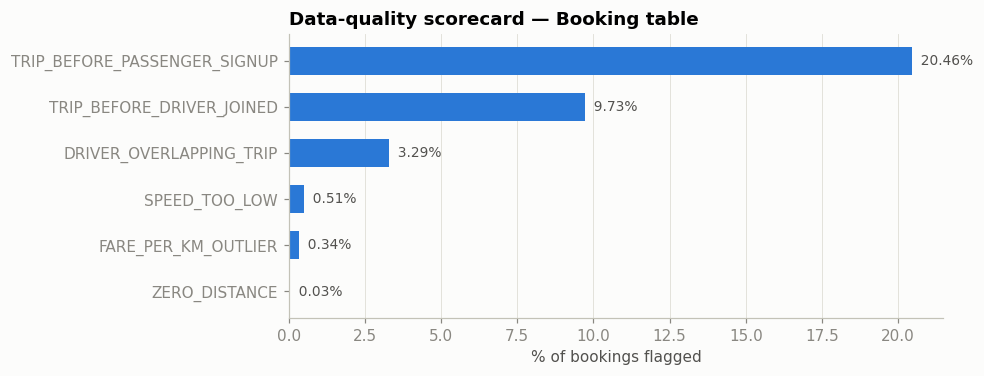

In [25]:
sc = scorecard.toPandas().sort_values("count")
fig, ax = plt.subplots(figsize=(9, 0.42 * len(sc) + 1))
ax.barh(sc["rule"], sc["pct_of_bookings"], color=PALETTE[0], height=0.6)
for y, v in enumerate(sc["pct_of_bookings"]):
    ax.text(v, y, f"  {v:.2f}%", va="center", color="#52514e", fontsize=9)
ax.set_xlabel("% of bookings flagged"); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Data-quality scorecard — Booking table"); plt.tight_layout(); plt.show()

**How to read it:** the row-level physics checks (speed, duration, waits) pass almost entirely. The serious problems are **relational**: trips that overlap the same driver's previous trip, and trips dated before the passenger registered or the driver joined. Those can't be fixed in BI. Raise them with the source-system owner and filter or flag them in dashboards (the `dq_clean` column makes that one click).

## 7 · Referential integrity across tables

In [26]:
p = raw["Payment"].withColumn("BookingID", F.col("BookingID").cast("int")).withColumn("Amount", F.col("Amount").cast("double"))
r = raw["Rewards"].withColumn("BookingID", F.regexp_extract("Description", r"#(\d+)", 1).cast("int"))   # built-in beats a UDF here
b_ids = bookings.select("BookingID")

def orphan_report(name, child, key, parent):
    n = child.count(); o = child.join(parent, key, "left_anti")
    stats = o.agg(F.count("*").alias("n"), F.min(key).alias("min_id"), F.max(key).alias("max_id")).first()
    return (name, n, stats["n"], round(stats["n"] / n * 100, 1), stats["min_id"], stats["max_id"])

ri = spark.createDataFrame([
    orphan_report("Payment → Booking", p, "BookingID", b_ids),
    orphan_report("Rewards → Booking", r, "BookingID", b_ids),
    orphan_report("Booking → Passenger", bookings, "PassengerID", pax_reg.select("PassengerID")),
    orphan_report("Booking → Driver", bookings, "DriverID", drv_join.select("DriverID")),
    orphan_report("Booking → Place (pickup)", bookings.withColumnRenamed("PickupPlaceID", "PlaceID"), "PlaceID",
                  raw["Place"].select(F.col("PlaceID").cast("int").alias("PlaceID"))),
], "relationship string, child_rows long, orphans long, orphan_pct double, orphan_min_id int, orphan_max_id int")
show(ri)
print("Max BookingID in Booking.csv:", bookings.agg(F.max("BookingID")).first()[0])

,relationship,child_rows,orphans,orphan_pct,orphan_min_id,orphan_max_id
0,Payment → Booking,962068,475664,49.4,505631.0,1000000.0
1,Rewards → Booking,931164,460175,49.4,505631.0,1000000.0
2,Booking → Passenger,505630,0,0.0,NaN,NaN
3,Booking → Driver,505630,0,0.0,NaN,NaN
4,Booking → Place (pickup),505630,0,0.0,NaN,NaN


Max BookingID in Booking.csv: 505630


In [27]:
pay_total = p.agg(F.sum("Amount")).first()[0]
pay_matched = p.join(b_ids, "BookingID").agg(F.sum("Amount")).first()[0]
print(f"Payments total    ${pay_total:,.0f}")
print(f"…matched to a booking ${pay_matched:,.0f}  ({pay_matched / pay_total:.1%})")
print("\nBookings with no payment, by booking status:")
show(bookings.join(p.select("BookingID"), "BookingID", "left_anti").groupBy("BookingStatus").count())

Payments total    $15,506,984
…matched to a booking $7,847,205  (50.6%)

Bookings with no payment, by booking status:


,BookingStatus,count
0,No Show,5068
1,Cancelled,14158


> **Finding: the Booking extract looks truncated.** Payment and Rewards reference BookingIDs up to **1,000,000**, but Booking.csv stops at **505,630**. Every orphan sits *above* that ID, so the gap is one contiguous block and not scattered bad keys.
> **Impact:** any dashboard that sums the Payment table on its own roughly **doubles revenue** compared with what the bookings support.
> **Action:** request the full Booking extract. Until then, the downstream notebooks **inner-join to bookings** (a bounded, consistent window).
>
> The bookings without a payment are exactly the No-Shows plus the cancellations that weren't charged a fee, which is expected behaviour.

## 8 · Write the silver layer

In [29]:
SILVER = os.path.join(LAKE_DIR, "silver")
(checked.withColumn("year_month", F.date_format("BookingTS", "yyyy-MM"))
        .write.mode("overwrite").partitionBy("year_month").parquet(f"{SILVER}/bookings"))
(p.select(F.col("PaymentID").cast("int"), "BookingID", F.col("PaymentTypeID").cast("int"), "Amount",
          F.to_timestamp("PaymentDateTime").alias("PaymentTS"), F.col("Status").alias("PaymentStatus"))
  .write.mode("overwrite").parquet(f"{SILVER}/payments"))
passengers_safe.write.mode("overwrite").parquet(f"{SILVER}/passengers_masked")
scorecard.coalesce(1).write.mode("overwrite").option("header", True).csv(os.path.join(LAKE_DIR, "gold", "dq_scorecard"))
print("Silver written to", SILVER)

# Disable vectorized reader to handle zero-byte FUSE sync files on Google Drive
spark.conf.set("spark.sql.parquet.enableVectorizedReader", "false")
try:
    print(spark.read.parquet(f"{SILVER}/bookings").groupBy("dq_clean").count().collect())
finally:
    spark.conf.set("spark.sql.parquet.enableVectorizedReader", "true")

Silver written to /content/drive/MyDrive/rebu/lakehouse/silver
[Row(dq_clean=True, count=351459), Row(dq_clean=False, count=154171)]


## Summary
| Area | Result |
|---|---|
| Timestamp parsing | 100% parsed; built-in is several × faster than the UDF, so use UDFs for logic, not plumbing |
| Phones | All numbers normalise to valid SG mobiles (E.164) |
| Addresses | 100% parsed; many passenger postcodes are invalid or disagree with the street, so geocode by street |
| PII | Masked email/phone and salted SHA-256 keys in `passengers_masked` |
| DQ engine | Physics checks pass; **overlapping driver trips** and **trips before sign-up/join** are the material issues |
| Integrity | **Booking extract truncated at ID 505,630**, so roughly half of payments and rewards have no booking |

**Next:** `02TripEnrichmentandPricing.ipynb` turns clean trips into geo, time and pricing intelligence.